# Классификация уровня дохода

## Цель проекта: 
**Необходимо по имеющимся признакам предсказать уровень дохода группы людей: более 50K или менее 50K**

### Признаки набора данных:
•	Возраст - age: continuous. \
•	Статус занятости человека - workclass: Private, Self-emp-not-inc, Self-emp-inc, Federal-gov, Local-gov, State-gov, Without-pay, Never-worked. \
•	Количество людей, согласно переписи, принадлежащих к той же группе  - fnlwgt: continuous.\
•	Уровень образования - education: Bachelors, Some-college, 11th, HS-grad, Prof-school, Assoc-acdm, Assoc-voc, 9th, 7th-8th, 12th, Masters, 1st-4th, 10th, Doctorate, 5th-6th, Preschool. \
•	Статус образования (сколько ступеней от дошкольного до докторантуры пройдено) education-num: continuous. \
•	Семейное положение - marital-status: Married-civ-spouse, Divorced, Never-married, Separated, Widowed, Married-spouse-absent, Married-AF-spouse. \
•	Область занятости - occupation: Tech-support, Craft-repair, Other-service, Sales, Exec-managerial, Prof-specialty, Handlers-cleaners, Machine-op-inspct, Adm-clerical, Farming-fishing, Transport-moving, Priv-house-serv, Protective-serv, Armed-Forces. \
•	Взаимоотношения - relationship: Wife, Own-child, Husband, Not-in-family, Other-relative, Unmarried. \
•	Раса - race: White, Asian-Pac-Islander, Amer-Indian-Eskimo, Other, Black. \
•	Пол - sex: Female, Male. \
•	Прирост капитала - capital-gain: continuous. \
•	Потеря капитала - capital-loss: continuous. \
•	Количество рабочих часов в неделю - hours-per-week: continuous. \
•	Родная страна - native-country: United-States, Cambodia, England, Puerto-Rico, Canada, Germany, Outlying-US(Guam-USVI-etc), India, Japan, Greece, South, China, Cuba, Iran, Honduras, Philippines, Italy, Poland, Jamaica, Vietnam, Mexico, Portugal, Ireland, France, Dominican-Republic, Laos, Ecuador, Taiwan, Haiti, Columbia, Hungary, Guatemala, Nicaragua, Scotland, Thailand, Yugoslavia, El-Salvador, Trinadad&Tobago, Peru, Hong, Holand-Netherlands.\

Целевая переменная: \
•	Доход - salary: <=50K or >50K \

**Источник данных:** Adult Census Income Dataset (UCI Machine Learning Repository)

### Задачи:
1.	Импортировать набор данных. Обработать выбросы и пропуски.
2.	Проверить гипотезу о влиянии признака education на целевую переменную.
3.	Выполнить укрупнение признака education и проверить влияние нового признака на результат.
4.	Построить график зависимости между результирующим признаком и статусом образования.
5.	Провести обработку признаков в зависимости от их типа и подготовить данные для построения классификатора.
6.	Разделить выборку на тестовую и обучающую.
7.	Провести отбор признаков в модель. 
8.	Построить классификатор с использованием модели логистической регрессии. 
9.	Валидировать модель. Подобрать гиперпараметры модели, максимизирующие метрику log_loss. 
10.	Оценить качество полученной модели.
11.	Оценить важность признаков. 

### Бизнес-метрика: Log Loss (логарифмическая функция потерь)

**Обоснование выбора:**\
В рамках проекта требуется максимизировать качество вероятностной классификации. 
Log Loss штрафует модель не только за неверные предсказания, но и за низкую уверенность 
в правильных предсказаниях. Это критически важно для бизнес-задачи, где важно не только 
определить, превышает ли доход человека 50K, но и оценить степень уверенности модели 
в этом предсказании.

Способ использования:
- Log Loss используется в качестве основной метрики при подборе гиперпараметров 
  (GridSearchCV с scoring='neg_log_loss')
- Интерпретация: чем ближе к 0, тем выше качество
- Базовый уровень = 0.5

### Библиотеки

In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn.metrics import log_loss, auc, accuracy_score, classification_report

#### 1.	Импортировать набор данных. Обработать выбросы и пропуски.

In [79]:
df = pd.read_csv('adult.csv')

In [80]:
df

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


In [81]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [82]:
df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64

ознакомление с данными: типы данных верные, пропусков в данных нет

In [83]:
# для удобства создадим столбец с целевым признаком на основе income (<=50K == 0 and >50K == 1)
df['target'] = df['income'].apply(lambda x: 1 if x == ' >50K' else 0)

In [84]:
df

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income,target
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K,0
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K,1
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K,0
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K,0


In [85]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,target
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456,0.240810
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429,0.427581
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000,0.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000,0.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000,0.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000,0.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000,1.000000


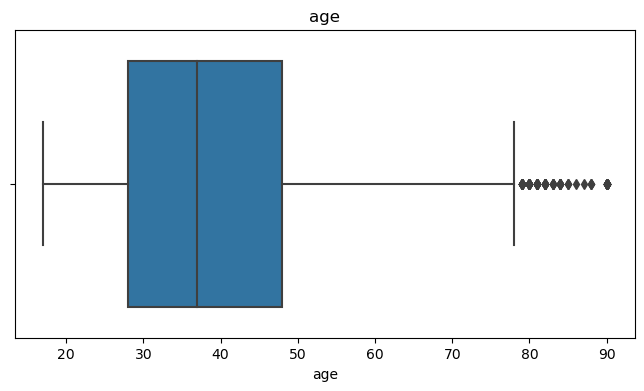

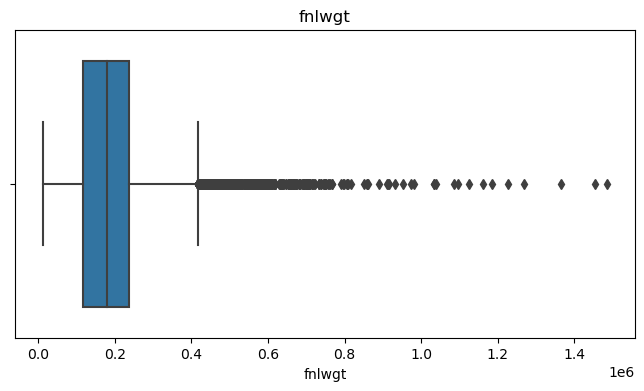

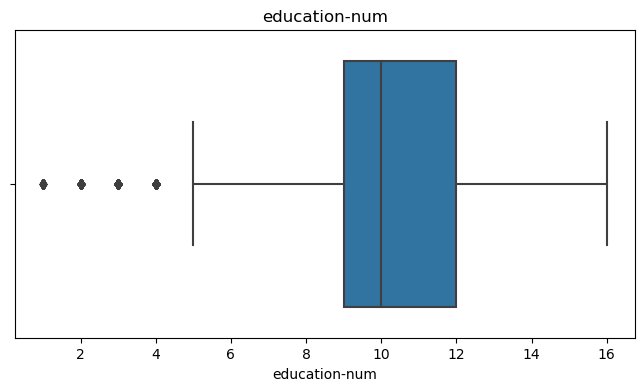

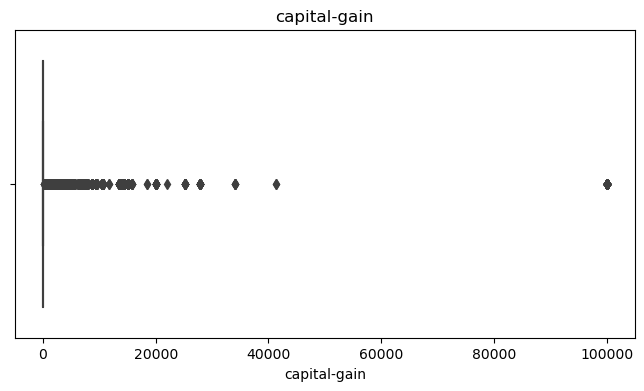

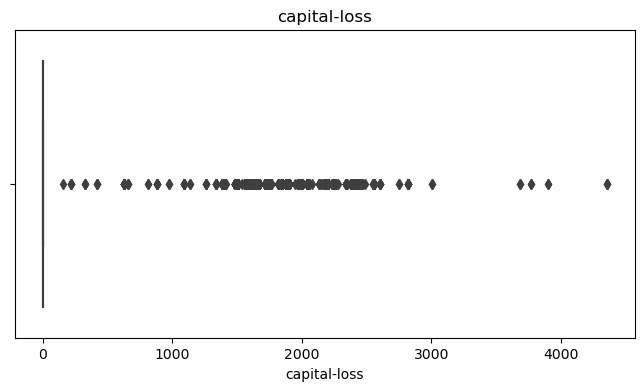

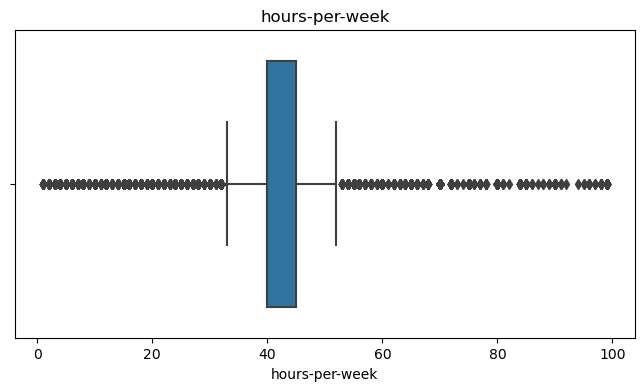

In [86]:
numerical_columns = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
for column in numerical_columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[column])
    plt.title(column)
    plt.show()

Выбросы:\

В столбцах capital-gain и capital-loss обнаружены значительные выбросы. 

Эти выбросы здесь удалять не буду, так как значения не единичные, это может исказить результаты, потому что приведет к потере важной информации для предсказания (а возможно, это окажется одним из ключевых факторов, так как по сути отражает финансовые операции).

In [87]:
#df[df['capital-gain'] > 90000]
#df[df['capital-loss'] > 3000]

В столбце hours-per-week также много выбросов в обе стороны.Их не удаляю, потому что они скорее всего соответствуют реальным режимам работы: неполнаят занятость или переработки.

In [88]:
#на всякий случай проверим категориальные перменные: 
#точно ли в них нет опечаток или лишних значений неправильно записанных
categorical_columns = ['workclass', 'education', 'marital-status', 'occupation', 
                       'relationship', 'race', 'sex', 'native-country', 'income']

for column in categorical_columns:
    unique_values = df[column].unique()
    print(f"Уникальные значения {column}:")
    print(unique_values)
    print()

Уникальные значения workclass:
[' State-gov' ' Self-emp-not-inc' ' Private' ' Federal-gov' ' Local-gov'
 ' ?' ' Self-emp-inc' ' Without-pay' ' Never-worked']

Уникальные значения education:
[' Bachelors' ' HS-grad' ' 11th' ' Masters' ' 9th' ' Some-college'
 ' Assoc-acdm' ' Assoc-voc' ' 7th-8th' ' Doctorate' ' Prof-school'
 ' 5th-6th' ' 10th' ' 1st-4th' ' Preschool' ' 12th']

Уникальные значения marital-status:
[' Never-married' ' Married-civ-spouse' ' Divorced'
 ' Married-spouse-absent' ' Separated' ' Married-AF-spouse' ' Widowed']

Уникальные значения occupation:
[' Adm-clerical' ' Exec-managerial' ' Handlers-cleaners' ' Prof-specialty'
 ' Other-service' ' Sales' ' Craft-repair' ' Transport-moving'
 ' Farming-fishing' ' Machine-op-inspct' ' Tech-support' ' ?'
 ' Protective-serv' ' Armed-Forces' ' Priv-house-serv']

Уникальные значения relationship:
[' Not-in-family' ' Husband' ' Wife' ' Own-child' ' Unmarried'
 ' Other-relative']

Уникальные значения race:
[' White' ' Black' ' Asian-P

в категориальных все значения начинаются с пробела!!! и есть знак вопроса для неизвестных значений

#### 2. Проверить гипотезу о влиянии признака education на целевую переменную.

в данном случае нужно проверить гипотезу влияния качественных признаков (education - категориальная перменная) на качественный (target). в таком случае лучше всего подходит тест Хи-квадрат.

Нулевая гипотеза Н0: education и целевая переменная независимы\
Альтернативная гипотеза Н1: связь есть

In [89]:
# Проверяем статистическую значимость связи между education и target
# Создаем таблицу сопряженности
contingency_table = pd.crosstab(df['education'], df['target'])

# Используем тест χ²
chi2, p, dof, expected = stats.chi2_contingency(contingency_table)
print(f"Хи-квадрат: chi2={chi2}, p-value={p}")
if p < 0.05:
    print("Нет оснований отвергнуть нулевую гипотезу о независимости. Между education и target есть статистически значимая связь.")
else:
    print("Нет статистически значимой связи между education и целевой переменной.")

Хи-квадрат: chi2=4429.653302288619, p-value=0.0
Нет оснований отвергнуть нулевую гипотезу о независимости. Между education и target есть статистически значимая связь.


#### 3.	Выполнить укрупнение признака education и проверить влияние нового признака на результат.

In [90]:
df['education'].unique()

array([' Bachelors', ' HS-grad', ' 11th', ' Masters', ' 9th',
       ' Some-college', ' Assoc-acdm', ' Assoc-voc', ' 7th-8th',
       ' Doctorate', ' Prof-school', ' 5th-6th', ' 10th', ' 1st-4th',
       ' Preschool', ' 12th'], dtype=object)

In [91]:
# укрупним данные по уровням образования и создадим новый столбец education_level
def education_level(row):
    if row in [ ' 5th-6th', ' 10th', ' 1st-4th', ' Preschool', ' 12th', ' 7th-8th', ' 9th', ' 11th']:
        return 'Basic'
    elif row in [' HS-grad', ' Some-college', ' Assoc-acdm', ' Assoc-voc']:
        return 'Intermediate'
    elif row in [' Bachelors', ' Masters',' Doctorate', ' Prof-school']:
        return 'Higher'
    else:
        return 'Unknown'

In [92]:
df['education_level'] = df['education'].apply(education_level)

In [93]:
#хи-квадрат тест
contingency_table_group = pd.crosstab(df['education_level'], df['target'])
chi2_group, p_group, dof_group, expected_group = stats.chi2_contingency(contingency_table_group)
print(f"Хи-квадрат: chi2={chi2_group}, p-value={p_group}")
if p_group < 0.05:
    print("Нет оснований отвергнуть нулевую гипотезу о независимости. Между education_level и target есть статистически значимая связь")
else:
    print("Нет статистически значимой связи между education_group и target")

Хи-квадрат: chi2=3784.876163173042, p-value=0.0
Нет оснований отвергнуть нулевую гипотезу о независимости. Между education_level и target есть статистически значимая связь


#### 4.	Построить график зависимости между результирующим признаком и статусом образования.

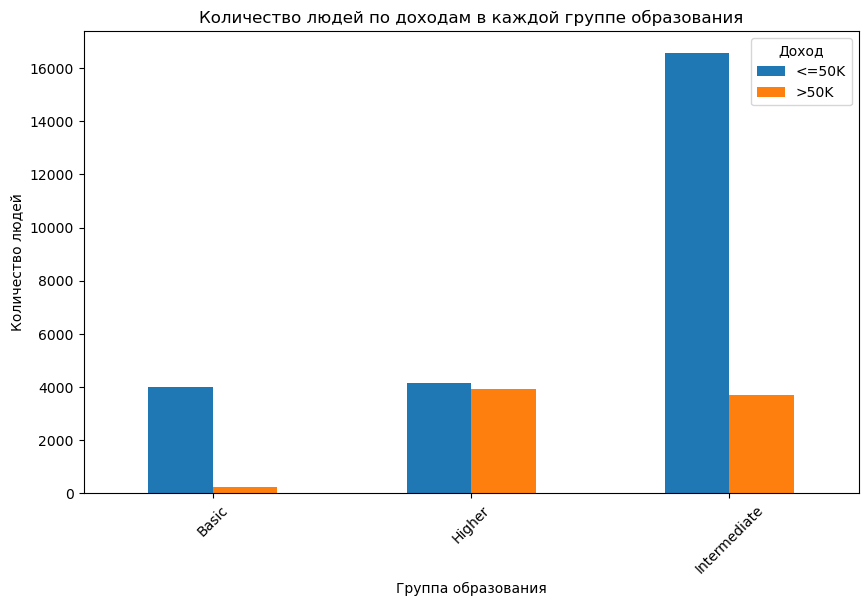

In [94]:
contingency_table_group.plot(kind='bar', stacked=False, figsize=(10, 6))

plt.title('Количество людей по доходам в каждой группе образования')
plt.xlabel('Группа образования')
plt.ylabel('Количество людей')
plt.xticks(rotation=45)
plt.legend(title='Доход', labels=['<=50K', '>50K'])
plt.show()


#### 5.	Провести обработку признаков в зависимости от их типа и подготовить данные для построения классификатора.

In [95]:
from sklearn.preprocessing import StandardScaler

In [96]:
X = df.drop(columns=['target', 'income', 'native-country'])
y = df['target']

In [97]:
categorical_columns = ['workclass', 'education', 'education_level', 'marital-status', 'occupation', 'relationship', 'race', 'sex']
numerical_columns = ['age', 'fnlwgt', 'capital-gain', 'capital-loss', 'hours-per-week', 'education-num']

# с 'education-num' конечно вопрос, так как категориальный признак, но у нас уже много факторов связанных с образованием
# поэтому оставим его в числовых

In [98]:
# создание фиктивных для категориальных признаков
X = pd.get_dummies(X, columns=categorical_columns, drop_first=True) #лучше OneHotEncoder!!!

# стандартизация числовых
scaler = StandardScaler()
X[numerical_columns] = scaler.fit_transform(X[numerical_columns])

In [99]:
X

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,workclass_ Federal-gov,workclass_ Local-gov,workclass_ Never-worked,workclass_ Private,...,relationship_ Not-in-family,relationship_ Other-relative,relationship_ Own-child,relationship_ Unmarried,relationship_ Wife,race_ Asian-Pac-Islander,race_ Black,race_ Other,race_ White,sex_ Male
0,0.030671,-1.063611,1.134739,0.148453,-0.21666,-0.035429,False,False,False,False,...,True,False,False,False,False,False,False,False,True,True
1,0.837109,-1.008707,1.134739,-0.145920,-0.21666,-2.222153,False,False,False,False,...,False,False,False,False,False,False,False,False,True,True
2,-0.042642,0.245079,-0.420060,-0.145920,-0.21666,-0.035429,False,False,False,True,...,True,False,False,False,False,False,False,False,True,True
3,1.057047,0.425801,-1.197459,-0.145920,-0.21666,-0.035429,False,False,False,True,...,False,False,False,False,False,False,True,False,False,True
4,-0.775768,1.408176,1.134739,-0.145920,-0.21666,-0.035429,False,False,False,True,...,False,False,False,False,True,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,-0.849080,0.639741,0.746039,-0.145920,-0.21666,-0.197409,False,False,False,True,...,False,False,False,False,True,False,False,False,True,False
32557,0.103983,-0.335433,-0.420060,-0.145920,-0.21666,-0.035429,False,False,False,True,...,False,False,False,False,False,False,False,False,True,True
32558,1.423610,-0.358777,-0.420060,-0.145920,-0.21666,-0.035429,False,False,False,True,...,False,False,False,True,False,False,False,False,True,False
32559,-1.215643,0.110960,-0.420060,-0.145920,-0.21666,-1.655225,False,False,False,True,...,False,False,True,False,False,False,False,False,True,True


#### 6.	Разделить выборку на тестовую и обучающую.

In [100]:
from sklearn.model_selection import train_test_split

In [101]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=88)

#### 7.	Провести отбор признаков в модель. 

проведем отбор признаков в модель с помощью логистической регрессии (20 самых важных)

In [102]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import log_loss
from sklearn.feature_selection import SelectFromModel

In [103]:
log_reg = LogisticRegression(max_iter=1000, random_state=88)
log_reg.fit(X_train, y_train)

#20 наиболее важных признаков
selector = SelectFromModel(log_reg, threshold="mean", max_features=20)
X_train_selected = selector.transform(X_train)
X_test_selected = selector.transform(X_test)

print("Selected features:", X.columns[selector.get_support()])

Selected features: Index(['education-num', 'capital-gain', 'workclass_ Federal-gov',
       'workclass_ Without-pay', 'education_ 5th-6th', 'education_ Preschool',
       'marital-status_ Married-AF-spouse',
       'marital-status_ Married-civ-spouse', 'occupation_ Exec-managerial',
       'occupation_ Farming-fishing', 'occupation_ Priv-house-serv',
       'occupation_ Prof-specialty', 'occupation_ Protective-serv',
       'occupation_ Tech-support', 'relationship_ Other-relative',
       'relationship_ Own-child', 'relationship_ Wife',
       'race_ Asian-Pac-Islander', 'race_ White', 'sex_ Male'],
      dtype='object')


C:\Users\Liza\anaconda3\lib\site-packages\sklearn\base.py:486: UserWarning:

X has feature names, but SelectFromModel was fitted without feature names

C:\Users\Liza\anaconda3\lib\site-packages\sklearn\base.py:486: UserWarning:

X has feature names, but SelectFromModel was fitted without feature names



#### 8. Построить классификатор с использованием модели логистической регрессии.

In [104]:
log_reg = LogisticRegression(max_iter=1000, random_state=88)
log_reg.fit(X_train_selected, y_train)

y_pred_prob = log_reg.predict_proba(X_test_selected)[:, 1]

# log_loss
loss = log_loss(y_test, y_pred_prob)
print(f"log_loss jn test: {loss}")

log_loss jn test: 0.3428128111441527


In [105]:
from sklearn.metrics import roc_curve, auc, log_loss
import plotly.express as px
import plotly.graph_objects as go

In [106]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
auc_value = auc(fpr, tpr)
print(auc_value)

fig = px.area(
    x=fpr, y=tpr, 
    labels={'x': 'False Positive Rate', 'y': 'True Positive Rate'}
)
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines", line=dict(color="gray", dash='dash')))
fig.show()

0.8897819162001585


#### 9.	Валидировать модель. Подобрать гиперпараметры модели, максимизирующие метрику log_loss.

In [107]:
from sklearn.model_selection import GridSearchCV

In [108]:
# Параметры для GridSearch
param_grid = {
    'penalty': ['l2'],  # L2 регуляризация
    'C': [0.01, 0.1, 1, 10, 100],  # Регуляризационный параметр np.arange(0.1, 1,0.1)
    'solver': ['lbfgs', 'liblinear'],  # Решатели для логистической регрессии
}

# Инициализация и запуск GridSearchCV
grid_search = GridSearchCV(LogisticRegression(max_iter=1000, random_state=88), param_grid, cv=5, scoring='neg_log_loss', n_jobs=-1)
grid_search.fit(X_train_selected, y_train)

# Выводим лучшие параметры и лучший log_loss
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best Log Loss: {-grid_search.best_score_}")

Best Parameters: {'C': 100, 'penalty': 'l2', 'solver': 'liblinear'}
Best Log Loss: 0.3383014243170486


**10.Оценить качество полученной модели.** 

In [109]:
# модель с лучшими параметрами
best_log_reg = grid_search.best_estimator_

y_pred_prob_best = best_log_reg.predict_proba(X_test_selected)[:, 1]
y_pred_best = best_log_reg.predict(X_test_selected)

# log loss
loss_best = log_loss(y_test, y_pred_prob_best)
print(f"Log Loss: {loss_best}")

Log Loss: 0.34291112708664934


In [110]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob_best)
auc_value = auc(fpr, tpr)
print(auc_value)

fig = px.area(
    x=fpr, y=tpr, 
    labels={'x': 'False Positive Rate', 'y': 'True Positive Rate'}
)
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines", line=dict(color="gray", dash='dash')))
fig.show()

0.8896682867270498


**11. Оценить важность признаков.**

In [111]:
selected_features = X_train.columns[selector.get_support()]

# коэффициенты модели
feature_importance = pd.DataFrame({
    'Feature': selected_features,
    'Importance': np.abs(best_log_reg.coef_[0])  # Модуль значений коэффициентов
})

feature_importance = feature_importance.sort_values(by='Importance', ascending=False)
feature_importance

,Feature,Importance
5,education_ Preschool,10.411814
10,occupation_ Priv-house-serv,4.622936
3,workclass_ Without-pay,4.057287
1,capital-gain,2.349754
6,marital-status_ Married-AF-spouse,2.142292
7,marital-status_ Married-civ-spouse,2.061336
15,relationship_ Own-child,1.738552
8,occupation_ Exec-managerial,1.000093
16,relationship_ Wife,0.874360
14,relationship_ Other-relative,0.866305


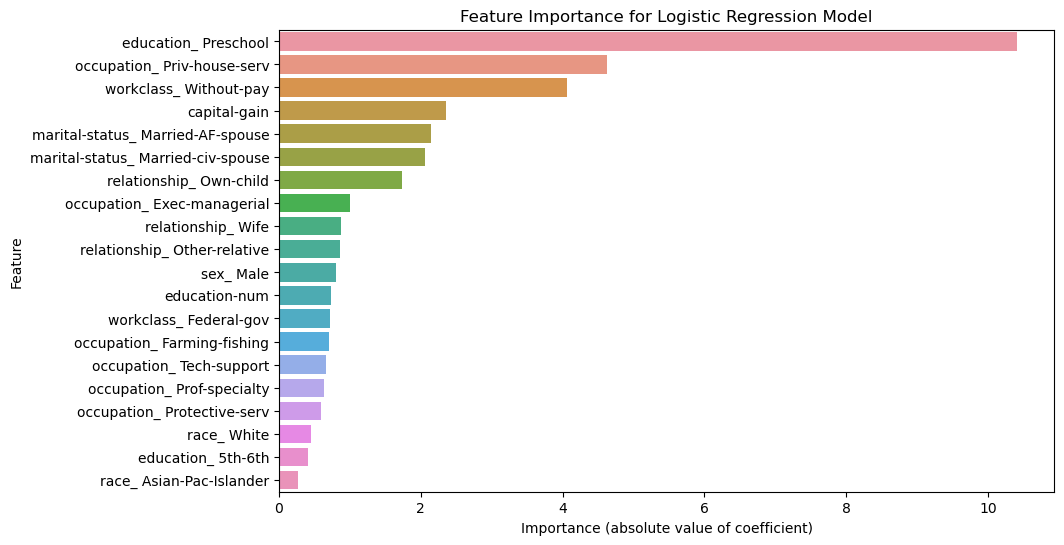

In [112]:
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance)
plt.title('Feature Importance for Logistic Regression Model')
plt.xlabel('Importance (absolute value of coefficient)')
plt.ylabel('Feature')
plt.show()

In [114]:
# Также посмотрим направление (положительное или отрицательное влияние)
feature_importance_with_sign = pd.DataFrame({
    'Feature': selected_features,
    'Importance': np.abs(best_log_reg.coef_[0]),
    'Coefficient': best_log_reg.coef_[0]  # знак
})
feature_importance_with_sign = feature_importance_with_sign.sort_values(by='Importance', ascending=False)
feature_importance_with_sign

,Feature,Importance,Coefficient
5,education_ Preschool,10.411814,-10.411814
10,occupation_ Priv-house-serv,4.622936,-4.622936
3,workclass_ Without-pay,4.057287,-4.057287
1,capital-gain,2.349754,2.349754
6,marital-status_ Married-AF-spouse,2.142292,2.142292
7,marital-status_ Married-civ-spouse,2.061336,2.061336
15,relationship_ Own-child,1.738552,-1.738552
8,occupation_ Exec-managerial,1.000093,1.000093
16,relationship_ Wife,0.874360,0.874360
14,relationship_ Other-relative,0.866305,-0.866305


## Выводы:
**Log Loss (=0.3429):** 
   - Значение ниже базового уровня (0.5)
   - Модель уверенно предсказывает вероятности, ошибки не сопровождаются ложной уверенностью

**ROC-AUC (=0.8897):** 
   - Показатель близок к 0.9, что свидетельствует о высоком качестве бинарной классификации
   - Модель хорошо различает людей с доходом менее 50K и более 50K

**Наиболее значимые признаки:**

1. education_ Preschool — наличие только дошкольного образования
2. occupation_ Priv-house-serv — работа в частном доме
3. workclass_ Without-pay — неоплачиваемая работа
4. capital-gain — прирост капитала
5. marital-status_ Married-AF-spouse — семейное положение

**Значение:**

- **Образование** — наличие только дошкольного образования (Preschool) значительно снижает вероятность высокого дохода. При этом более высокие уровни образования (education-num, 5th-6th) связаны с повышением вероятности. 
- **Занятость** — неоплачиваемая работа (Without-pay) и работа в частном доме (Priv-house-serv) являются сильными негативными факторами. Руководящие должности (Exec-managerial) наоборот положительно влияют на доход. 
- **Финансовые показатели** — прирост капитала значимо связан с высоким доходом.
- **Семейное положение** — состоящие в браке имеют более высокий доход, а статус собственный ребенок (Own-child) влияет отрицательно.


**Итог:**
   - Модель демонстрирует хорошее качество и пригодна для решения поставленной задачи.
   - Модель выделила логически обоснованные признаки, что подтверждает ее адекватность.